<a href="https://colab.research.google.com/github/rercampos/PreparandoAmbiente/blob/main/wordcloud_avaliacoes_clientes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Word Clouds de avaliações de clientes: uma análise exploratória em Python

*Análise exploratória de textos com Python, NLTK e Word Cloud, usando 20 mil avaliações reais da base B2W-Reviews01.*

| | |
|---|---|
| **Componente curricular** | Projeto e Análise de Visualização do Conhecimento |
| **Atividade** | Aplicando o conhecimento 3 |
| **Aluno** | Reginaldo Rogério de Campos |
| **RA** | 10743942 |

Nesta atividade, realiza-se uma análise exploratória de textos a partir de uma base pública de avaliações de
usuários, com o objetivo de identificar os termos mais frequentes e compreender quais temas aparecem com maior
destaque nos textos analisados.

---
## 1. Descrição da base de dados

A B2W-Reviews01 é uma base de dados pública de avaliações de produtos redigidas por clientes da loja virtual
Americanas.com. Cada linha é uma avaliação de um produto e traz o texto escrito pelo cliente, a nota em estrelas,
a indicação se ele recomendaria o produto, a categoria do produto e dados do avaliador (ano de nascimento, gênero
e estado). Os comentários estão em português e cobrem categorias variadas, como celulares, informática,
eletrodomésticos, livros e utilidades domésticas.

A base foi escolhida por reunir grande volume de comentários e por registrar a nota de cada avaliação (1 a 5
estrelas), o que permite separar clientes satisfeitos e insatisfeitos e comparar o vocabulário de cada grupo.

### 1.1 Informação da base de dados

- **Nome:** B2W-Reviews01
- **Fonte:** B2W Digital (Americanas.com), descrita em Real, Oshiro e Mafra (2019)
- **Link:** https://github.com/americanas-tech/b2w-reviews01
- **Quantidade de registros:** 132.373 avaliações
- **Total de colunas da base:** 14
- **Colunas utilizadas na análise:**
  - `review_text` — o comentário escrito pelo cliente;
  - `overall_rating` — a nota de 1 a 5 estrelas;
  - `recommend_to_a_friend` — se o cliente recomendaria o produto (Yes/No).

**Amostragem.** Em razão do volume da base (132.373 avaliações), a análise foi conduzida sobre uma amostra
aleatória simples de 20.000 avaliações, extraída com `df.sample(20000, random_state=42)`. O tamanho da amostra
supera em 40 vezes o mínimo exigido (500 comentários) e reduz o custo computacional da análise. A fixação da
semente aleatória (`random_state=42`) assegura a reprodutibilidade: qualquer execução do código seleciona
exatamente as mesmas avaliações e, portanto, produz os mesmos resultados. A base foi carregada diretamente do
repositório oficial no GitHub, por meio da biblioteca pandas, e a amostra foi extraída em seguida.

In [1]:
import re
import random
import textwrap
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import wordpunct_tokenize
from wordcloud import WordCloud

nltk.download('stopwords', quiet=True)

pd.set_option('display.max_colwidth', 120)
plt.rcParams['figure.dpi'] = 110

In [2]:
URL = 'https://raw.githubusercontent.com/americanas-tech/b2w-reviews01/main/B2W-Reviews01.csv'

df_completo = pd.read_csv(URL, low_memory=False)
print('Base completa:', df_completo.shape[0], 'linhas e', df_completo.shape[1], 'colunas')

Base completa: 132373 linhas e 14 colunas


In [3]:
df = df_completo.sample(20000, random_state=42).reset_index(drop=True)
print('Amostra:', df.shape[0], 'linhas')

Amostra: 20000 linhas


Para verificar a representatividade da amostra, comparou-se a distribuição percentual das notas na base completa
e na amostra. As proporções diferem em no máximo 0,6 ponto percentual, o que indica que a amostra é
representativa quanto a esse atributo.

In [4]:
comparacao = pd.DataFrame({
    'Base completa (%)': df_completo['overall_rating'].value_counts(normalize=True).sort_index() * 100,
    'Amostra (%)': df['overall_rating'].value_counts(normalize=True).sort_index() * 100,
}).round(1)
comparacao.index.name = 'Nota'
print(comparacao)

      Base completa (%)  Amostra (%)
Nota                                
1                  20.7         20.6
2                   6.3          6.3
3                  12.3         12.2
4                  24.4         25.0
5                  36.2         35.9


---
## 2. Exploração inicial dos dados

### 2.1 Quantidade de linhas, colunas e nome das colunas

A amostra é composta por 20.000 linhas e 14 colunas, cujos nomes são listados a seguir.

In [5]:
print('Linhas e colunas da amostra:', df.shape)
print('\nNomes das colunas:')
for coluna in df.columns:
    print(' -', coluna)

Linhas e colunas da amostra: (20000, 14)

Nomes das colunas:
 - submission_date
 - reviewer_id
 - product_id
 - product_name
 - product_brand
 - site_category_lv1
 - site_category_lv2
 - review_title
 - overall_rating
 - recommend_to_a_friend
 - review_text
 - reviewer_birth_year
 - reviewer_gender
 - reviewer_state


### 2.2 Quantidade de valores ausentes na coluna de texto

Foram contabilizados os registros sem texto (valor NaN) e os registros com texto composto apenas por espaços.
Na coluna `review_text`, foram identificados 496 comentários ausentes (2,5% da amostra), sem ocorrência de textos
compostos apenas por espaços.

In [6]:
nulos = df['review_text'].isna().sum()
vazios = (df['review_text'].fillna('').str.strip() == '').sum()
print('Comentários nulos (NaN) em review_text:', nulos)
print('Comentários vazios ou nulos (total):', vazios)

Comentários nulos (NaN) em review_text: 496
Comentários vazios ou nulos (total): 496


### 2.3 Alguns exemplos de comentários

Os exemplos evidenciam características típicas de textos escritos por usuários, como variação no uso de
maiúsculas, pontuação repetida, abreviações e erros de digitação, aspectos tratados na etapa de pré-processamento.

In [7]:
print('Exemplos de comentários:\n')
exemplos = df.dropna(subset=['review_text']).sample(5, random_state=1)
for _, linha in exemplos.iterrows():
    print(f"[Nota {linha['overall_rating']}]")
    print(textwrap.fill(linha['review_text'], width=80, initial_indent='  ', subsequent_indent='  '))
    print()

Exemplos de comentários:

[Nota 4]
  muito bom produto  não tenho o que reclamar veio o modelo que escolhi chegou
  antes do prazo estimado

[Nota 1]
  As panelas são de péssima qualidade. Usei apenas uma vez. Queimou o fundo e
  não sai por nada, sem contar que usei em fogo baixo. A comida queima antes de
  ficar pronta.

[Nota 4]
  Na verdade o produto não mim serve. Houve engano ou falta de atenção na hora
  da compra.

[Nota 5]
  Efetuei a compra mas sem muitas expectativas. Quando eu usei o fone de ouvido
  pela primeira vez já fiquei com o sorriso largo. O som de ótima qualidade !!!
  Recomendadissimo !!!

[Nota 4]
  Comprei para minha sobrinha, ela está adorando. Chegou bem antes do combinado,
  adoro comprar na Americana



### 2.4 Remoção dos comentários vazios e quantidade de comentários que serão efetivamente utilizados na análise

Os 496 comentários vazios ou nulos foram removidos, por não conterem palavras a serem analisadas. Desse modo,
19.504 comentários foram efetivamente utilizados na análise.

In [8]:
df = df[df['review_text'].fillna('').str.strip() != ''].reset_index(drop=True)
print('Comentários efetivamente utilizados na análise:', len(df))

Comentários efetivamente utilizados na análise: 19504


---
## 3. Pré-processamento dos textos

Antes da análise, os comentários foram submetidos ao seguinte tratamento:

- **Conversão para letras minúsculas**, para que variações como "Bom", "BOM" e "bom" sejam contabilizadas como
  uma única palavra.
- **Remoção de pontuação**, incluindo símbolos e emojis, por meio da expressão regular `[^\w\s]`.
- **Remoção de números**, por não serem relevantes para a identificação dos temas (preços, quantidades e datas).
- **Tokenização**, isto é, a separação de cada comentário em palavras (*tokens*), com a função
  `wordpunct_tokenize` da biblioteca NLTK.
- **Remoção de *stopwords***, com a lista do NLTK para o português (207 termos), acrescida de 11 termos:
  "produto", "nao", "pra", "pois", "ter", "ser", "vai", "fica", "fazer", "outro" e "outra". O termo "produto" foi
  incluído por ocorrer 10.674 vezes na amostra; como todas as avaliações se referem a um produto, ele não
  distingue temas e dominaria a Word Cloud. "Nao" é a grafia sem acento de "não", já presente na lista original,
  e os demais são palavras funcionais frequentes na escrita informal.
- **Remoção de palavras muito curtas**, com até duas letras, como "é", "eu", "ok" e "vc".

In [9]:
stop_pt = set(stopwords.words('portuguese'))
stop_extras = {'produto', 'nao', 'pra', 'pois', 'ter', 'ser', 'vai', 'fica',
               'fazer', 'outro', 'outra'}
stop_total = stop_pt | stop_extras


def preprocessar(texto):
    texto = texto.lower()                                  # conversão para minúsculas
    texto = re.sub(r'[^\w\s]', ' ', texto)                 # remoção de pontuação
    texto = texto.replace('_', ' ')
    texto = re.sub(r'\d+', ' ', texto)                     # remoção de números
    tokens = wordpunct_tokenize(texto)                     # tokenização
    tokens = [t for t in tokens if t not in stop_total]    # remoção de stopwords
    tokens = [t for t in tokens if len(t) > 2]             # remoção de palavras curtas
    return tokens


df['tokens'] = df['review_text'].apply(preprocessar)
df['texto_limpo'] = df['tokens'].apply(' '.join)

for _, linha in df.head(3).iterrows():
    print('ORIGINAL:      ', linha['review_text'])
    print('PRÉ-PROCESSADO:', linha['texto_limpo'], '\n')

contagem_bruta = Counter(t for tokens in df['review_text'].str.lower().str.findall(r'\w+') for t in tokens)
print("Ocorrências de 'produto' antes da remoção:", contagem_bruta['produto'])

ORIGINAL:       Ele e muito bom ,bom, bom , bom , bom. BOM BOM BOM Tao bom ,que fica ruim.
PRÉ-PROCESSADO: bom bom bom bom bom bom bom bom tao bom ruim 

ORIGINAL:       cumpre a funcao desejada melhor que a marca concorrente
PRÉ-PROCESSADO: cumpre funcao desejada melhor marca concorrente 

ORIGINAL:       Não tem luz então não funciona a noite. Sem manual não acerta de jeito nenhum. O meu veio com o pé quebrado e devolveram o dinheiro
PRÉ-PROCESSADO: luz então funciona noite manual acerta jeito nenhum veio quebrado devolveram dinheiro 

Ocorrências de 'produto' antes da remoção: 10674


Observa-se, no terceiro exemplo, que a negação "não" é removida por integrar a lista de *stopwords*, de modo que
"não funciona" passa a "funciona". Essa limitação é discutida na seção 7.

**Por que o pré-processamento é necessário antes da construção da Word Cloud?**

A Word Cloud representa cada termo com tamanho proporcional à sua frequência no conjunto de textos. Por isso, a
qualidade da visualização depende diretamente da contagem das palavras. Sem pré-processamento, variações de uma
mesma palavra, como "Bom", "bom" e "bom!", seriam contabilizadas como termos distintos, o que fragmenta a
frequência real e reduz o destaque de termos relevantes. Além disso, palavras funcionais de alta ocorrência, como
artigos, preposições e conjunções ("de", "que", "o", "a"), ocupariam as posições de maior destaque na nuvem sem
acrescentar informação sobre o conteúdo dos comentários. Números, sinais de pontuação e palavras muito curtas
também introduziriam ruído. O pré-processamento padroniza o texto e mantém apenas os termos portadores de
significado, de modo que a Word Cloud reflita os temas efetivamente abordados pelos usuários.

---
## 4. Frequência das palavras

Após o pré-processamento, a frequência de cada palavra foi obtida com a classe `Counter`, do módulo
`collections`, e armazenada em um dicionário no formato `{palavra: frequência}`. No total, os 19.504 comentários
resultaram em 234.114 palavras, das quais 18.053 são distintas. A tabela e o gráfico a seguir apresentam as 15
palavras mais frequentes.

In [10]:
todas_palavras = [t for tokens in df['tokens'] for t in tokens]
frequencia = dict(Counter(todas_palavras))   # dicionário {palavra: frequência}

print('Total de palavras após o pré-processamento:', len(todas_palavras))
print('Palavras distintas:', len(frequencia))
print('\nTrecho do dicionário {palavra: frequência}:')
print(dict(list(frequencia.items())[:10]))

top15 = pd.DataFrame(Counter(frequencia).most_common(15), columns=['Palavra', 'Frequência'])
top15.index = range(1, 16)
print('\n', top15)

Total de palavras após o pré-processamento: 234114
Palavras distintas: 18053

Trecho do dicionário {palavra: frequência}:
{'bom': 3946, 'tao': 19, 'ruim': 343, 'cumpre': 310, 'funcao': 1, 'desejada': 5, 'melhor': 715, 'marca': 364, 'concorrente': 4, 'luz': 88}

        Palavra  Frequência
1          bom        3946
2    recomendo        3794
3      entrega        3518
4          bem        2549
5    qualidade        2533
6       chegou        2423
7        prazo        2382
8    excelente        2278
9        antes        1863
10     comprei        1846
11       ótimo        1819
12  americanas        1781
13       super        1678
14      gostei        1588
15         boa        1447


### 4.1 Frequência das palavras e as 15 palavras mais frequentes

**Tabela 1 – As 15 palavras mais frequentes**

| # | Palavra | Frequência |
|---|---|---|
| 1 | bom | 3.946 |
| 2 | recomendo | 3.794 |
| 3 | entrega | 3.518 |
| 4 | bem | 2.549 |
| 5 | qualidade | 2.533 |
| 6 | chegou | 2.423 |
| 7 | prazo | 2.382 |
| 8 | excelente | 2.278 |
| 9 | antes | 1.863 |
| 10 | comprei | 1.846 |
| 11 | ótimo | 1.819 |
| 12 | americanas | 1.781 |
| 13 | super | 1.678 |
| 14 | gostei | 1.588 |
| 15 | boa | 1.447 |

### 4.2 Gráfico de barras

A Figura 1 representa as mesmas 15 palavras em um gráfico de barras horizontais, ordenadas da maior para a menor
frequência. A visualização evidencia a proximidade entre as duas primeiras palavras, "bom" e "recomendo",
separadas por apenas 152 ocorrências, e a diferença entre as três primeiras e as demais: a partir de "bem", as
frequências caem para menos de 2.600 ocorrências.

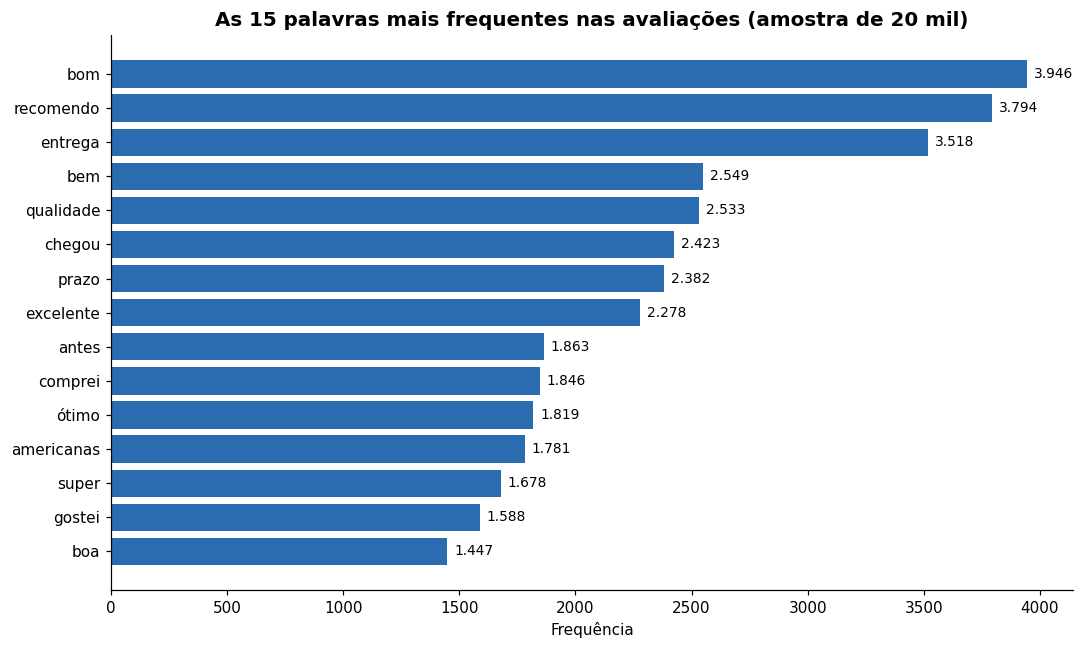

In [11]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top15['Palavra'][::-1], top15['Frequência'][::-1], color='#2B6CB0')
for i, valor in enumerate(top15['Frequência'][::-1]):
    ax.text(valor + 30, i, f'{valor:,}'.replace(',', '.'), va='center', fontsize=9)
ax.set_title('As 15 palavras mais frequentes nas avaliações (amostra de 20 mil)', fontsize=13, weight='bold')
ax.set_xlabel('Frequência')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('fig1_top15.png', dpi=150, bbox_inches='tight')
plt.show()

*Figura 1 – As 15 palavras mais frequentes nos comentários analisados*

---
## 5. Word Cloud

Na nuvem de palavras, o tamanho de cada palavra é proporcional à sua frequência, o que confere maior destaque aos
termos mais recorrentes. Como as frequências já estavam armazenadas no dicionário obtido na seção 4,
utilizou-se o método `generate_from_frequencies`, que constrói a nuvem diretamente a partir dessas contagens.

Parâmetros principais:

- `max_words=150`: limita a nuvem a 150 palavras, preservando a legibilidade;
- `collocations=False`: impede que pares de palavras frequentes sejam agrupados como um único termo;
- `random_state=42`: fixa a disposição das palavras, garantindo o mesmo resultado em qualquer execução;
- `background_color='white'`: define o fundo branco da imagem;
- `color_func`: define as cores das palavras. Foi criada a função `paleta`, que atribui a cada palavra uma cor
  sorteada de uma lista de tons escuros de azul e verde-azulado. Tons claros, como o amarelo, foram evitados por
  apresentarem baixo contraste com o fundo branco.

A visualização recebeu o título "Word Cloud geral — avaliações de produtos da Americanas.com", definido com
`plt.title`.

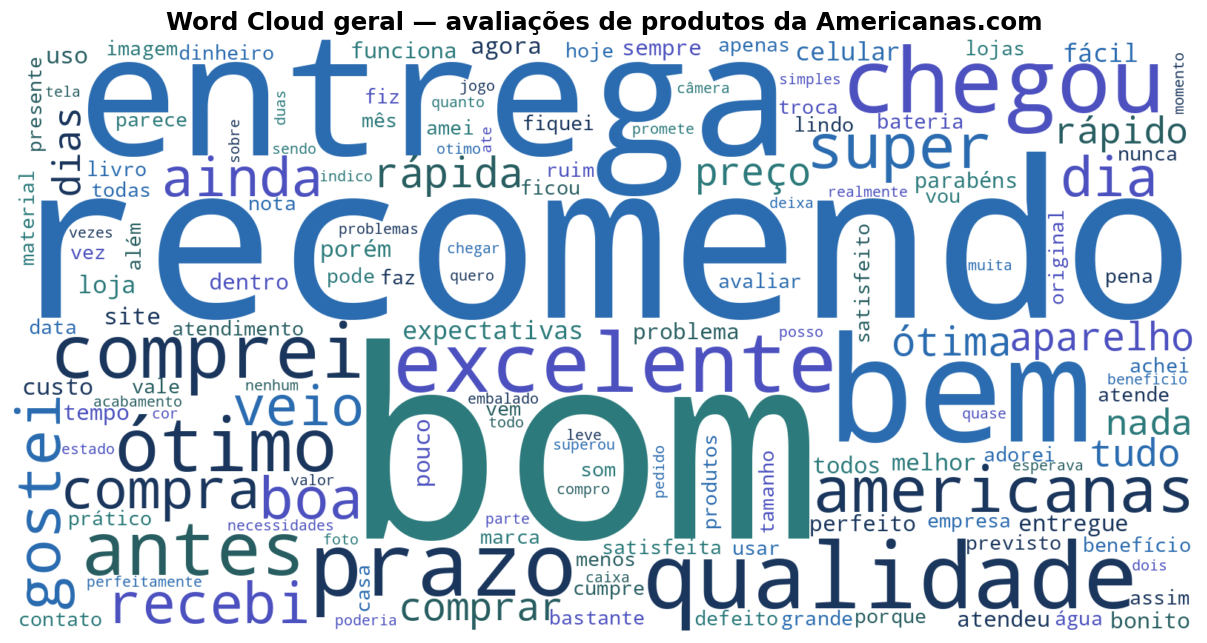

In [12]:
def paleta(cores):
    def colorir(*args, **kwargs):
        return random.choice(cores)
    return colorir


random.seed(42)
nuvem_geral = WordCloud(width=1600, height=800, background_color='white',
                        max_words=150, collocations=False, random_state=42,
                        color_func=paleta(['#1A365D', '#2B6CB0', '#2C7A7B', '#285E61', '#4C51BF'])
                        ).generate_from_frequencies(frequencia)

plt.figure(figsize=(14, 7))
plt.imshow(nuvem_geral, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud geral — avaliações de produtos da Americanas.com', fontsize=16, weight='bold')
plt.savefig('fig2_wordcloud_geral.png', dpi=150, bbox_inches='tight')
plt.show()

*Figura 2 – Word Cloud geral dos comentários analisados*

A Figura 2 apresenta a Word Cloud geral. Os termos de maior destaque — "bom", "recomendo" e "entrega" —
coincidem com as primeiras posições da Tabela 1.

---
## 6. Comparando dois grupos: notas altas × notas baixas

Para a comparação, os comentários foram divididos em dois grupos, a partir do atributo `overall_rating`:
**notas altas**, com avaliações de 4 ou 5 estrelas (12.026 comentários), e **notas baixas**, com avaliações de 1
ou 2 estrelas (5.076 comentários). As avaliações com 3 estrelas, de caráter neutro, foram excluídas desta etapa
para acentuar o contraste entre os grupos. Para cada grupo, foram calculadas as frequências das palavras e gerada
uma Word Cloud, com verde para o grupo de notas altas e vermelho para o de notas baixas.

**Separação dos grupos e frequências:**

In [13]:
altas = df[df['overall_rating'] >= 4]
baixas = df[df['overall_rating'] <= 2]
print('Avaliações com nota alta (4-5):', len(altas))
print('Avaliações com nota baixa (1-2):', len(baixas))

freq_altas = Counter(t for tokens in altas['tokens'] for t in tokens)
freq_baixas = Counter(t for tokens in baixas['tokens'] for t in tokens)

top_grupos = pd.DataFrame({
    'Notas altas': [f'{p} ({n})' for p, n in freq_altas.most_common(15)],
    'Notas baixas': [f'{p} ({n})' for p, n in freq_baixas.most_common(15)],
}, index=range(1, 16))
print(top_grupos)

Avaliações com nota alta (4-5): 12026
Avaliações com nota baixa (1-2): 5076
         Notas altas      Notas baixas
1   recomendo (3070)     recebi (1055)
2         bom (2881)    comprei (1000)
3     entrega (2538)  americanas (866)
4   excelente (2156)        veio (732)
5   qualidade (1906)       ainda (695)
6         bem (1851)     entrega (637)
7       prazo (1791)         dia (603)
8       ótimo (1664)      compra (580)
9      chegou (1649)        nada (562)
10      antes (1566)      chegou (551)
11      super (1532)        dias (472)
12     gostei (1148)       agora (445)
13        boa (1020)   recomendo (441)
14      rápida (976)   qualidade (404)
15       ótima (944)        site (391)


**Word Clouds dos dois grupos**

As duas nuvens foram dispostas lado a lado, com tons de verde para o grupo de notas altas e de vermelho para o de
notas baixas.

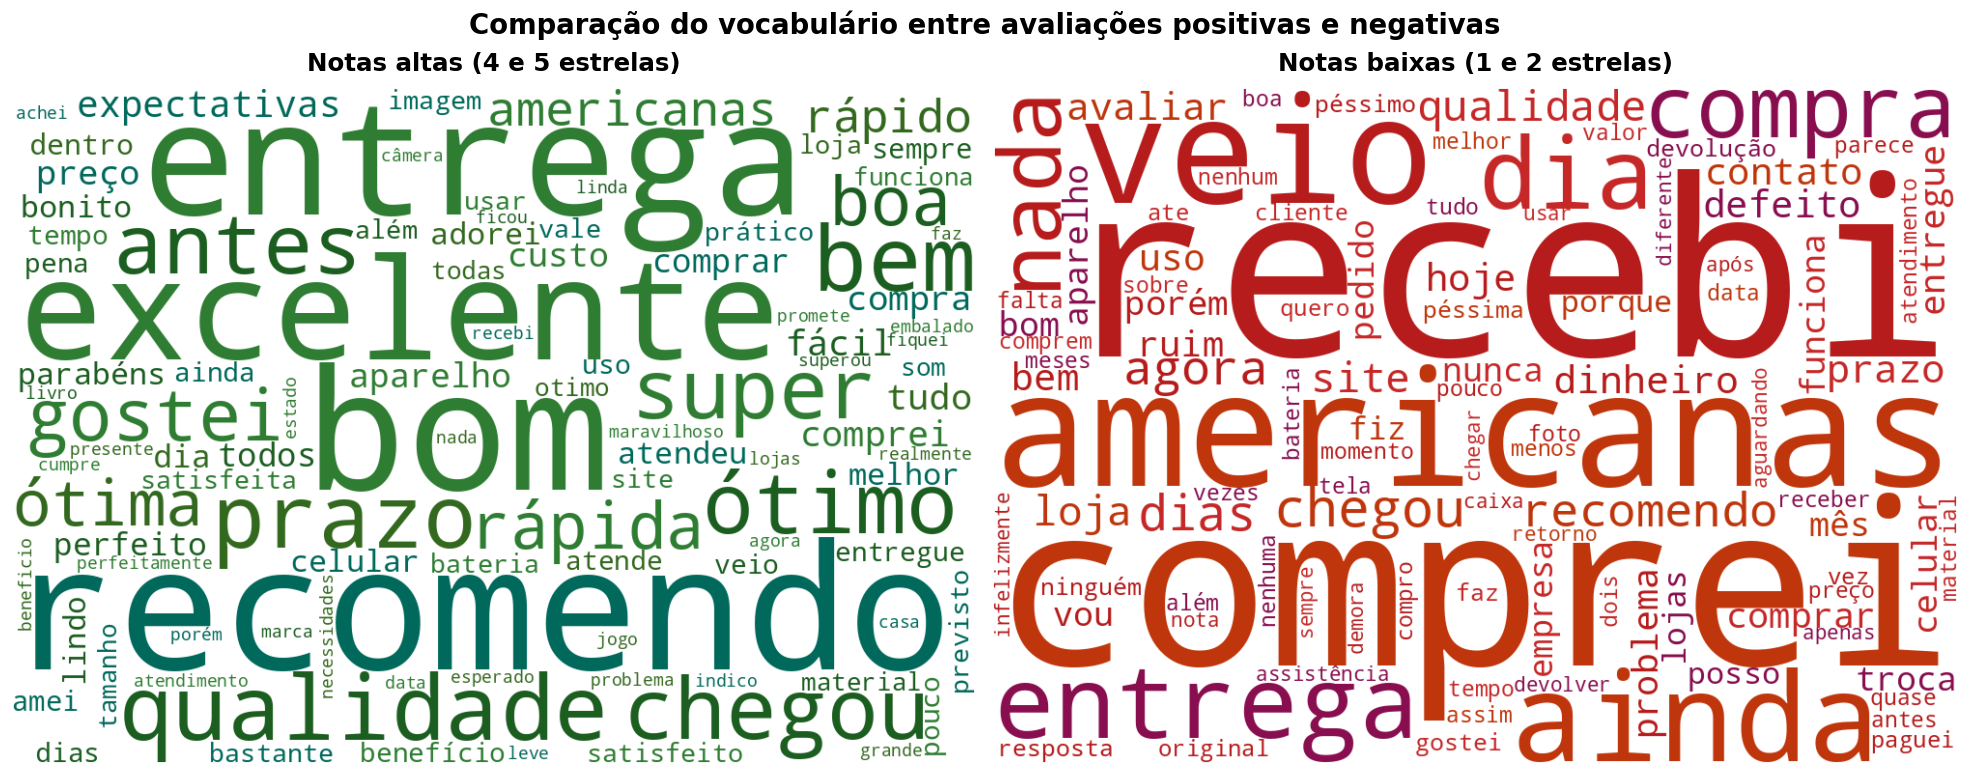

In [14]:
random.seed(42)
nuvem_altas = WordCloud(width=1000, height=700, background_color='white', max_words=100,
                        collocations=False, random_state=42,
                        color_func=paleta(['#1B5E20', '#2E7D32', '#00695C', '#33691E'])
                        ).generate_from_frequencies(freq_altas)
nuvem_baixas = WordCloud(width=1000, height=700, background_color='white', max_words=100,
                         collocations=False, random_state=42,
                         color_func=paleta(['#B71C1C', '#C62828', '#BF360C', '#880E4F'])
                         ).generate_from_frequencies(freq_baixas)

fig, eixos = plt.subplots(1, 2, figsize=(18, 7))
for ax, nuvem, titulo in [(eixos[0], nuvem_altas, 'Notas altas (4 e 5 estrelas)'),
                          (eixos[1], nuvem_baixas, 'Notas baixas (1 e 2 estrelas)')]:
    ax.imshow(nuvem, interpolation='bilinear')
    ax.set_title(titulo, fontsize=16, weight='bold', pad=12)
    ax.axis('off')
plt.tight_layout()
plt.suptitle('Comparação do vocabulário entre avaliações positivas e negativas',
             fontsize=18, weight='bold', y=1.04)
plt.savefig('fig3_wordclouds_grupos.png', dpi=150, bbox_inches='tight')
plt.show()

*Figura 3 – Word Clouds dos comentários com notas altas (à esquerda) e notas baixas (à direita)*

**Termos predominantes em cada grupo**

Como os grupos têm tamanhos diferentes, os termos característicos de cada um foram identificados pela frequência
relativa, isto é, as ocorrências de cada palavra divididas pelo total de palavras do grupo. Foram consideradas
apenas palavras com pelo menos 40 ocorrências, e a Tabela 3 apresenta os dez termos mais característicos de cada
grupo.

In [15]:
total_altas = sum(freq_altas.values())
total_baixas = sum(freq_baixas.values())

linhas = []
for palavra in set(freq_altas) | set(freq_baixas):
    n_a, n_b = freq_altas[palavra], freq_baixas[palavra]
    if n_a + n_b >= 40:
        prop_a = (n_a + 1) / total_altas
        prop_b = (n_b + 1) / total_baixas
        linhas.append((palavra, n_a, n_b, prop_a / prop_b))

razoes = pd.DataFrame(linhas, columns=['Palavra', 'Notas altas', 'Notas baixas', 'Razão altas/baixas'])
print('Termos característicos das NOTAS ALTAS:')
print(razoes.sort_values('Razão altas/baixas', ascending=False).head(10).round(2).to_string(index=False))
print('\nTermos característicos das NOTAS BAIXAS:')
print(razoes.sort_values('Razão altas/baixas').head(10).round(3).to_string(index=False))

Termos característicos das NOTAS ALTAS:
  Palavra  Notas altas  Notas baixas  Razão altas/baixas
   adorei          462             1              153.11
     amei          386             1              127.98
   adorou          128             0               85.32
  superou          247             1               82.01
     amou          104             0               69.44
 parabéns          492             7               40.76
   ótimas           60             0               40.34
    ótima          944            16               36.76
excelente         2156            38               36.58
    otimo          260             4               34.52

Termos característicos das NOTAS BAIXAS:
     Palavra  Notas altas  Notas baixas  Razão altas/baixas
   reembolso            0            46               0.014
      procon            0            44               0.015
      sequer            0            43               0.015
     retorno            2           129            

**Tabela 2 – As 15 palavras mais frequentes em cada grupo**

| # | Notas altas | Notas baixas |
|---|---|---|
| 1 | recomendo (3.070) | recebi (1.055) |
| 2 | bom (2.881) | comprei (1.000) |
| 3 | entrega (2.538) | americanas (866) |
| 4 | excelente (2.156) | veio (732) |
| 5 | qualidade (1.906) | ainda (695) |
| 6 | bem (1.851) | entrega (637) |
| 7 | prazo (1.791) | dia (603) |
| 8 | ótimo (1.664) | compra (580) |
| 9 | chegou (1.649) | nada (562) |
| 10 | antes (1.566) | chegou (551) |
| 11 | super (1.532) | dias (472) |
| 12 | gostei (1.148) | agora (445) |
| 13 | boa (1.020) | recomendo (441) |
| 14 | rápida (976) | qualidade (404) |
| 15 | ótima (944) | site (391) |

**Tabela 3 – Termos característicos de cada grupo (ocorrências em notas altas / notas baixas)**

| Notas altas | Altas | Baixas | Notas baixas | Altas | Baixas |
|---|---|---|---|---|---|
| adorei | 462 | 1 | reembolso | 0 | 46 |
| amei | 386 | 1 | procon | 0 | 44 |
| adorou | 128 | 0 | sequer | 0 | 43 |
| superou | 247 | 1 | retorno | 2 | 129 |
| amou | 104 | 0 | enviei | 1 | 41 |
| parabéns | 492 | 7 | decepcionada | 5 | 123 |
| ótimas | 60 | 0 | devolução | 9 | 201 |
| ótima | 944 | 16 | horrível | 4 | 97 |
| excelente | 2.156 | 38 | péssima | 9 | 183 |
| otimo | 260 | 4 | solicitei | 5 | 94 |

**a. Quais palavras aparecem com maior destaque em cada grupo?**
No grupo de notas altas, destacam-se "recomendo", "bom", "entrega", "excelente", "qualidade", "ótimo", "prazo" e
"antes", termos que expressam avaliação positiva do produto e da entrega realizada antes do prazo. No grupo de
notas baixas, predominam "recebi", "comprei", "americanas", "veio", "ainda", "dia" e "nada": formas verbais e
marcadores de tempo que compõem relatos de problemas no processo de compra, como em "comprei no dia tal e ainda
não recebi nada".

**b. Existem termos que aparecem predominantemente em apenas um dos grupos?**
Sim. Conforme a Tabela 3, "adorei" (462 ocorrências nas notas altas e 1 nas baixas), "amei" (386 e 1), "superou"
(247 e 1) e "parabéns" (492 e 7) são praticamente exclusivos das notas altas. Já "reembolso" (0 e 46), "procon"
(0 e 44), "retorno" (2 e 129), "devolução" (9 e 201) e "péssima" (9 e 183) concentram-se nas notas baixas e
remetem ao pós-venda e a reclamações formais.

**c. As diferenças encontradas ajudam a compreender melhor as opiniões dos usuários?**
Sim. A comparação indica que a avaliação positiva se apoia no produto e na rapidez da entrega, enquanto a
avaliação negativa se concentra no processo de compra: atraso, não recebimento, troca, devolução e ausência de
resposta. Essa distinção não aparece na Word Cloud geral, na qual predominam as avaliações positivas, por serem
mais numerosas.

---
## 7. Análise dos resultados

Para fundamentar a interpretação, foram calculados três indicadores complementares a partir dos dados já
processados: a quantidade de ocorrências de "recomendo" no grupo de notas baixas que provém da expressão "não
recomendo"; a extensão média dos comentários, em número de palavras, em cada grupo; e a frequência relativa do
termo "americanas" em cada grupo, expressa em ocorrências por mil palavras. Os resultados são citados nas
respostas a seguir.

In [16]:
# Negação: quantos "recomendo" das notas baixas vêm de "não recomendo"
recomendo_baixas = freq_baixas['recomendo']
nao_recomendo = baixas['review_text'].str.lower().str.contains(r'n[ãa]o recomendo').sum()
print(f"Ocorrências de 'recomendo' nas notas baixas: {recomendo_baixas}")
print(f"Comentários com nota baixa que contêm 'não recomendo': {nao_recomendo}")

# Extensão média dos comentários em cada grupo
print(f"Média de palavras por comentário: altas = {altas['tokens'].str.len().mean():.1f} | "
      f"baixas = {baixas['tokens'].str.len().mean():.1f}")

# Frequência relativa de "americanas" em cada grupo (por mil palavras)
print(f"'americanas' por mil palavras: altas = {freq_altas['americanas'] / total_altas * 1000:.1f} | "
      f"baixas = {freq_baixas['americanas'] / total_baixas * 1000:.1f}")

Ocorrências de 'recomendo' nas notas baixas: 441
Comentários com nota baixa que contêm 'não recomendo': 394
Média de palavras por comentário: altas = 10.3 | baixas = 16.1
'americanas' por mil palavras: altas = 6.3 | baixas = 10.6


### 7.1 Quais foram as palavras mais frequentes?

As palavras mais frequentes foram "bom" (3.946 ocorrências), "recomendo" (3.794) e "entrega" (3.518), seguidas
de "bem", "qualidade", "chegou", "prazo", "excelente", "antes", "comprei", "ótimo", "americanas", "super",
"gostei" e "boa". Antes de sua inclusão na lista de *stopwords*, o termo "produto" ocupava a primeira posição,
com 10.674 ocorrências.

### 7.2 Quais temas parecem dominar os comentários?

Identificam-se quatro temas principais:

- **satisfação com o produto:** "bom", "ótimo", "excelente", "gostei", "super" e "boa";
- **entrega e prazo:** "entrega", "chegou", "prazo", "antes" e "rápida". É o tema mais recorrente depois da
  satisfação geral, o que indica que, no comércio eletrônico, a experiência de entrega pesa na avaliação de forma
  comparável ao próprio produto;
- **qualidade e preço:** "qualidade", "preço" e "custo";
- **recomendação:** "recomendo" é a segunda palavra mais frequente, o que é coerente com o atributo
  `recommend_to_a_friend`, no qual cerca de 73% dos registros da base completa indicam recomendação.

### 7.3 Quais diferenças foram encontradas entre os dois grupos analisados?

O grupo de notas altas emprega adjetivos de elogio ("excelente", "ótimo") e verbos de afeto ("adorei", "amei"),
além de referências à entrega rápida. O grupo de notas baixas emprega verbos e marcadores de tempo ("recebi",
"comprei", "veio", "ainda", "dia") e termos de pós-venda ("devolução", "reembolso", "Procon"). O termo "entrega"
aparece nos dois grupos com sentidos opostos: elogio à rapidez em um e reclamação de atraso no outro. Os
comentários negativos são também mais longos, com média de 16,1 palavras após o pré-processamento, contra 10,3 nos
positivos, o que indica que o cliente insatisfeito tende a relatar em detalhe o problema ocorrido.

### 7.4 A frequência das palavras e a Word Cloud contam a mesma história?

Sim, quanto ao conteúdo, já que a Word Cloud foi gerada a partir do mesmo dicionário de frequências: os termos de
maior destaque na nuvem coincidem com as primeiras posições do gráfico de barras. As duas representações, porém,
se complementam. O gráfico de barras permite a leitura precisa da ordem e dos valores — por exemplo, a
proximidade entre "bom" e "recomendo", pouco perceptível na nuvem. A Word Cloud oferece uma visão de conjunto de um
número maior de termos, mas a posição e a cor das palavras não carregam informação, e o comprimento de cada
palavra interfere na percepção do seu tamanho.

### 7.5 Existe alguma limitação em utilizar apenas a frequência de palavras para compreender as opiniões dos usuários?

Sim. As principais limitações identificadas foram:

- **perda da negação:** como "não" faz parte da lista de *stopwords*, "não recomendo" é reduzido a "recomendo".
  Das 441 ocorrências de "recomendo" no grupo de notas baixas, 394 vêm de comentários com a expressão "não
  recomendo";
- **ausência de contexto:** cada palavra é contada isoladamente. "Entrega" pode fazer parte de um elogio ou de uma
  reclamação, e "bem" pode ocorrer em "funciona bem" ou em "não funciona bem";
- **variações não unificadas:** sem lematização, formas como "ótimo", "ótima", "otimo" e "ótimas" são contadas
  separadamente, efeito agravado por erros de digitação e abreviações;
- **peso dos comentários longos:** quem escreve mais contribui com mais palavras. Como os comentários negativos
  são cerca de 57% mais longos, eles pesam mais na contagem do que seu número sugere;
- **escolhas metodológicas:** a lista de *stopwords* adicionais e o corte das notas (4–5 e 1–2) influenciam os
  resultados.

Técnicas como a análise de pares de palavras (bigramas, que preservariam "não recomendo"), a lematização e a
análise de sentimento poderiam complementar a contagem de frequências e incorporar o contexto ausente nesta
análise.

---
## 8. Conclusão

A análise exploratória de 19.504 avaliações da base B2W-Reviews01 permitiu identificar, por meio da frequência de
palavras e de Word Clouds, os temas que predominam nos comentários de clientes de comércio eletrônico. A
satisfação com o produto e a experiência de entrega concentram a maior parte do vocabulário, o que indica que,
para o consumidor on-line, receber o produto no prazo pesa na avaliação de forma comparável à qualidade do que foi
comprado.

A comparação entre os grupos mostrou que avaliações positivas e negativas diferem não apenas no tom, mas no
assunto: enquanto os clientes satisfeitos descrevem o produto e elogiam a rapidez da entrega, os insatisfeitos
relatam problemas no processo de compra, como atrasos, não recebimento, devoluções e falta de resposta da loja.
Essa distinção não é perceptível na Word Cloud geral, o que evidencia o valor da análise por grupos.

Por outro lado, a análise também evidenciou os limites da contagem de palavras: a remoção da negação, a ausência
de contexto e a falta de normalização morfológica podem distorcer a interpretação, como mostra o caso de "não
recomendo", reduzido a "recomendo". Conclui-se que a Word Cloud é uma ferramenta eficaz para uma primeira
aproximação de grandes volumes de texto, mas deve ser complementada por técnicas que considerem o contexto, como a
análise de bigramas e a análise de sentimento, para uma compreensão mais fiel das opiniões dos usuários.

---
## Referências

REAL, L.; OSHIRO, M.; MAFRA, A. B2W-Reviews01: an open product reviews corpus. In: SIMPÓSIO BRASILEIRO DE
TECNOLOGIA DA INFORMAÇÃO E DA LINGUAGEM HUMANA (STIL), 2019. Disponível em:
https://github.com/americanas-tech/b2w-reviews01. Acesso em: 28 out. 2026.

BIRD, S.; KLEIN, E.; LOPER, E. *Natural Language Processing with Python*. Sebastopol: O'Reilly Media, 2009.

MUELLER, A. *WordCloud for Python*. Disponível em: https://amueller.github.io/word_cloud/. Acesso em: 28 out. 2026.